# Sinh toy curve có order B-smooth trên $\mathbb{F}_p$

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Sinh toy curve có order chứa thừa số nguyên tố nhỏ* <br>

### Quá trình thực hiện
| Bước | Nội dung | Hàm chính |
|---|---|---|
| 1 | Nạp lại lõi số học từ `toy_curve_gen` (hoặc bản sao nội bộ) | import / fallback |
| 2 | Ước lượng chi phí tấn công theo phân tích thừa số (BSGS vs Pohlig–Hellman) | `estimate_bsgs_cost`, `estimate_ph_cost`, `ph_speedup` |
| 3 | Trích xuất hồ sơ độ "smooth" của một bản ghi D1 | `smoothness_profile` |
| 4 | Sinh **hàng loạt** curve smooth theo lưới `(n_bits × bound B)` & ghi CSV phân tích | `generate_smooth_curve_batch`, `write_analysis_csv` |
| 5 | Selftest & giao diện dòng lệnh (CLI) | `selftest`, `main` |
| 6 | **Demo**: sinh lô D1 mẫu, kiểm chứng, vẽ biểu đồ chi phí theo $B$ & kiểm tra bắt lỗi | `load_csv`, `verify_row` |

## Bước 1 – Nạp lại lõi số học từ `toy_curve_gen`

Ta có `curves/toy_curve_gen.py` là **file chạy chính**; notebook này import trực tiếp từ
đó nếu đã có trong cùng thư mục `curves/`. Nếu chạy độc lập, các cell dưới sẽ
**tự định nghĩa lại** đúng các hàm/lớp cần thiết đảm bảo chương trình vẫn chạy được mà không cần file ngoài.

In [1]:
from __future__ import annotations
import argparse, csv, json, random, sys
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from math import gcd, isqrt, prod, sqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

# Tự động dò tìm thư mục gốc dự án (chứa thư mục curves/) bất kể mở notebook từ đâu
cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
SCRIPTS_DIR = ROOT_DIR / "scripts"

for path in (str(ROOT_DIR), str(SCRIPTS_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)

try:
    # Dùng được khi curves/toy_curve_gen.py nằm cùng thư mục
    from toy_curve_gen import (
        Point, Curve, D1_COLUMNS, GENERATION_METHOD,
        is_prime, random_prime, factorize, sqrt_mod,
        count_points, count_points_naive, count_points_bsgs,
        classify, make_row, verify_row, write_csv, load_csv, parse_csv_row,
        generate_curve, git_commit,
    )
    print("Đã import lõi số học từ toy_curve_gen.py (cùng thư mục curves/).")
except ImportError:
    print("Không tìm thấy toy_curve_gen.py -> dùng bản sao lõi số học nội bộ (tự chứa).")

    Point = Optional[Tuple[int, int]]
    GENERATION_METHOD = "gen_smooth_curves.v1 (lõi kế thừa toy_curve_gen.v1)"
    NAIVE_COUNT_LIMIT = 1 << 16

    D1_COLUMNS = [
        "curve_id", "p", "a", "b", "discriminant", "discriminant_ok",
        "E_count", "E_count_factorization", "base_point_x", "base_point_y",
        "subgroup_n", "n_bits", "n_factorization", "cofactor_h",
        "largest_prime_factor_n", "is_anomalous", "is_supersingular", "category",
        "source_for_point_class", "small_order_available", "generation_method",
        "seed", "notes", "git_commit", "created_at",
    ]
    _JSON_COLUMNS = {"E_count_factorization", "n_factorization", "small_order_available"}
    _BOOL_COLUMNS = {"discriminant_ok", "is_anomalous", "is_supersingular"}
    _INT_COLUMNS = {"n_bits", "seed"}

    _MR_BASES = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)

    def is_prime(n: int) -> bool:
        if n < 2:
            return False
        for q in _MR_BASES:
            if n % q == 0:
                return n == q
        d, s = n - 1, 0
        while d % 2 == 0:
            d //= 2; s += 1
        for a in _MR_BASES:
            x = pow(a, d, n)
            if x in (1, n - 1):
                continue
            for _ in range(s - 1):
                x = x * x % n
                if x == n - 1:
                    break
            else:
                return False
        return True

    def random_prime(rng: random.Random, bits: int) -> int:
        if bits < 8:
            raise ValueError("bits phải >= 8 cho toy curve")
        while True:
            cand = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
            if is_prime(cand):
                return cand

    def _pollard_rho(n: int) -> int:
        rng = random.Random(n)
        while True:
            c = rng.randrange(1, n)
            x = y = rng.randrange(0, n)
            d = 1
            while d == 1:
                x = (x * x + c) % n
                y = (y * y + c) % n
                y = (y * y + c) % n
                d = gcd(abs(x - y), n)
            if d != n:
                return d

    def factorize(n: int) -> Dict[int, int]:
        if n < 1:
            raise ValueError("n phải >= 1")
        out: Dict[int, int] = {}
        d = 2
        while d < 5000 and d * d <= n:
            while n % d == 0:
                out[d] = out.get(d, 0) + 1
                n //= d
            d += 1 if d == 2 else 2

        def rec(m: int) -> None:
            if m == 1:
                return
            if is_prime(m):
                out[m] = out.get(m, 0) + 1
                return
            f = _pollard_rho(m)
            rec(f); rec(m // f)

        rec(n)
        return dict(sorted(out.items()))

    def sqrt_mod(n: int, p: int) -> Optional[int]:
        n %= p
        if n == 0:
            return 0
        if pow(n, (p - 1) // 2, p) != 1:
            return None
        if p % 4 == 3:
            return pow(n, (p + 1) // 4, p)
        q, s = p - 1, 0
        while q % 2 == 0:
            q //= 2; s += 1
        z = 2
        while pow(z, (p - 1) // 2, p) != p - 1:
            z += 1
        m, c, t, r = s, pow(z, q, p), pow(n, q, p), pow(n, (q + 1) // 2, p)
        while t != 1:
            i, t2 = 0, t
            while t2 != 1:
                t2 = t2 * t2 % p; i += 1
            b = pow(c, 1 << (m - i - 1), p)
            m, c = i, b * b % p
            t, r = t * c % p, r * b % p
        return r

    @dataclass(frozen=True)
    class Curve:
        p: int; a: int; b: int

        def discriminant(self) -> int:
            return (4 * pow(self.a, 3, self.p) + 27 * self.b * self.b) % self.p

        def is_nonsingular(self) -> bool:
            return self.discriminant() != 0

        def rhs(self, x: int) -> int:
            return (x * x * x + self.a * x + self.b) % self.p

        def contains(self, P: Point) -> bool:
            if P is None:
                return True
            x, y = P
            return 0 <= x < self.p and 0 <= y < self.p and (y * y - self.rhs(x)) % self.p == 0

        def neg(self, P: Point) -> Point:
            return None if P is None else (P[0], (-P[1]) % self.p)

        def add(self, P: Point, Q: Point) -> Point:
            if P is None:
                return Q
            if Q is None:
                return P
            p = self.p
            x1, y1 = P; x2, y2 = Q
            if x1 == x2:
                if (y1 + y2) % p == 0:
                    return None
                lam = (3 * x1 * x1 + self.a) * pow(2 * y1, -1, p) % p
            else:
                lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
            x3 = (lam * lam - x1 - x2) % p
            return (x3, (lam * (x1 - x3) - y1) % p)

        def mul(self, k: int, P: Point) -> Point:
            if k < 0:
                return self.mul(-k, self.neg(P))
            R: Point = None
            while k:
                if k & 1:
                    R = self.add(R, P)
                P = self.add(P, P)
                k >>= 1
            return R

        def random_point(self, rng: random.Random) -> Tuple[int, int]:
            while True:
                x = rng.randrange(self.p)
                y = sqrt_mod(self.rhs(x), self.p)
                if y is not None:
                    return (x, y if rng.getrandbits(1) else (-y) % self.p)

        def point_order(self, P: Point, group_order: int, factors: Dict[int, int]) -> int:
            order = group_order
            for q in factors:
                while order % q == 0 and self.mul(order // q, P) is None:
                    order //= q
            return order

        @staticmethod
        def from_row(row: dict) -> "Curve":
            return Curve(int(row["p"]), int(row["a"]), int(row["b"]))

        @staticmethod
        def base_point_from_row(row: dict) -> Tuple[int, int]:
            return (int(row["base_point_x"]), int(row["base_point_y"]))

    def count_points_naive(E: Curve) -> int:
        sq = Counter(y * y % E.p for y in range(E.p))
        return 1 + sum(sq.get(E.rhs(x), 0) for x in range(E.p))

    def _hasse_candidates(E: Curve, P, lo: int, hi: int) -> List[int]:
        m = isqrt(hi - lo + 1) + 1
        baby: Dict[Point, List[int]] = {}
        R: Point = None
        for j in range(m):
            baby.setdefault(R, []).append(j)
            R = E.add(R, P)
        giant_step = E.neg(R)
        T = E.neg(E.mul(lo, P))
        found: List[int] = []
        for i in range(m):
            for j in baby.get(T, ()):
                N = lo + i * m + j
                if N <= hi:
                    found.append(N)
            T = E.add(T, giant_step)
        return found

    def count_points_bsgs(E: Curve, rng: Optional[random.Random] = None, max_points: int = 40) -> int:
        rng = rng or random.Random(E.p)
        w = 2 * isqrt(E.p) + 2
        lo, hi = E.p + 1 - w, E.p + 1 + w
        cands: Optional[List[int]] = None
        for _ in range(max_points):
            P = E.random_point(rng)
            if cands is None:
                c = _hasse_candidates(E, P, lo, hi)
                if len(c) > 10000:
                    continue
                cands = c
            else:
                cands = [N for N in cands if E.mul(N, P) is None]
            if len(cands) == 1:
                return cands[0]
            if not cands:
                raise RuntimeError("count_points_bsgs: không còn ứng viên")
        raise RuntimeError("count_points_bsgs: không xác định được duy nhất #E")

    def count_points(E: Curve, rng: Optional[random.Random] = None) -> int:
        return count_points_naive(E) if E.p < NAIVE_COUNT_LIMIT else count_points_bsgs(E, rng)

    def _fact_list(f: Dict[int, int]) -> List[dict]:
        return [{"prime": str(q), "exponent": e} for q, e in f.items()]

    def classify(p: int, N: int, n: int, h: int, fn: Dict[int, int], smooth_bound: Optional[int]) -> str:
        if N == p:
            return "anomalous"
        if N == p + 1:
            return "supersingular"
        n_prime = len(fn) == 1 and next(iter(fn.values())) == 1
        if n_prime and h == 1:
            return "safe_prime_order"
        if n_prime and h > 1:
            return "cofactor_gt1"
        if smooth_bound is not None and max(fn) <= smooth_bound:
            return "smooth_order"
        return "smooth_order" if max(fn) < 1 << 20 else "cofactor_gt1"

    def _utc_now() -> str:
        return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

    def git_commit() -> str:
        try:
            import subprocess
            return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"],
                                            stderr=subprocess.DEVNULL).decode().strip()
        except Exception:
            return "0000000"

    def make_row(E: Curve, G, N: int, fN: Dict[int, int], n: int, fn: Dict[int, int],
                 seed: int, curve_id: str, smooth_bound: Optional[int] = None,
                 notes: Optional[str] = None, commit: Optional[str] = None) -> dict:
        h = N // n
        disc = E.discriminant()
        return {
            "curve_id": curve_id, "p": str(E.p), "a": str(E.a), "b": str(E.b),
            "discriminant": str(disc), "discriminant_ok": disc != 0,
            "E_count": str(N), "E_count_factorization": _fact_list(fN),
            "base_point_x": str(G[0]), "base_point_y": str(G[1]),
            "subgroup_n": str(n), "n_bits": n.bit_length(),
            "n_factorization": _fact_list(fn),
            "cofactor_h": str(h), "largest_prime_factor_n": str(max(fn)),
            "is_anomalous": N == E.p, "is_supersingular": N == E.p + 1,
            "category": classify(E.p, N, n, h, fn, smooth_bound),
            "source_for_point_class": None, "small_order_available": None,
            "generation_method": GENERATION_METHOD, "seed": seed,
            "notes": notes, "git_commit": commit or git_commit(), "created_at": _utc_now(),
        }

    MODES = ("prime", "cofactor", "smooth")

    def generate_curve(n_bits: int, mode: str = "prime", seed: int = 0, max_cofactor: int = 16,
                        smooth_bound: Optional[int] = None, allow_special: bool = False,
                        max_tries: int = 200000, curve_id: Optional[str] = None) -> dict:
        if mode not in MODES:
            raise ValueError(f"mode phải thuộc {MODES}")
        if n_bits < 8:
            raise ValueError("n_bits phải >= 8")
        if mode == "smooth" and smooth_bound is None:
            smooth_bound = 1 << max(4, n_bits // 3)
        rng = random.Random(seed)
        cid = curve_id or f"crv-{seed & 0xFFFFFFFF:08x}"

        for _ in range(max_tries):
            p_bits = n_bits + rng.randint(1, max(1, max_cofactor.bit_length() - 1)) if mode == "cofactor" else n_bits
            p = random_prime(rng, p_bits)
            E = Curve(p, rng.randrange(p), rng.randrange(p))
            if not E.is_nonsingular():
                continue
            try:
                N = count_points(E, rng)
            except RuntimeError:
                continue
            if (N == p or N == p + 1) and not allow_special:
                continue
            fN = factorize(N)
            qmax = max(fN)

            if mode == "prime":
                if len(fN) != 1 or fN[qmax] != 1 or N.bit_length() != n_bits:
                    continue
                n, fn, G = N, fN, E.random_point(rng)
            elif mode == "cofactor":
                h = N // qmax
                if not (fN[qmax] == 1 and 2 <= h <= max_cofactor and qmax.bit_length() == n_bits):
                    continue
                n, fn = qmax, {qmax: 1}
                P = E.random_point(rng)
                G = E.mul(h, P)
                if G is None:
                    continue
            else:  # smooth
                if qmax > smooth_bound or N.bit_length() < n_bits:
                    continue
                best, best_n = None, 0
                for _t in range(20):
                    P = E.random_point(rng)
                    o = E.point_order(P, N, fN)
                    if o > best_n:
                        best, best_n = P, o
                n = best_n
                if n.bit_length() != n_bits or len(factorize(n)) < 2:
                    continue
                fn, G = factorize(n), best
            return make_row(E, G, N, fN, n, fn, seed, cid, smooth_bound=smooth_bound, notes=f"mode={mode}")
        raise RuntimeError(f"Không sinh được curve (n_bits={n_bits}, mode={mode}) sau {max_tries} lần thử")

    def _to_cell(col: str, v):
        if v is None:
            return ""
        if col in _JSON_COLUMNS:
            return json.dumps(v, separators=(",", ":"))
        if col in _BOOL_COLUMNS:
            return "true" if v else "false"
        return str(v)

    def parse_csv_row(raw: dict) -> dict:
        row: dict = {}
        for col in D1_COLUMNS:
            v = raw.get(col, "")
            if col in _JSON_COLUMNS:
                row[col] = json.loads(v) if v else None
            elif col in _BOOL_COLUMNS:
                row[col] = v.strip().lower() == "true"
            elif col in _INT_COLUMNS:
                row[col] = int(v)
            else:
                row[col] = v if v != "" else None
        return row

    def write_csv(rows: List[dict], path: str, append: bool = False) -> None:
        path_ = Path(path)
        path_.parent.mkdir(parents=True, exist_ok=True)
        exists = append and path_.exists() and path_.stat().st_size > 0
        with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if not exists:
                w.writerow(D1_COLUMNS)
            for r in rows:
                w.writerow([_to_cell(c, r.get(c)) for c in D1_COLUMNS])

    def load_csv(path: str) -> List[dict]:
        with open(path, newline="", encoding="utf-8") as f:
            return [parse_csv_row(r) for r in csv.DictReader(f)]

    def verify_row(row: dict, recount: bool = True) -> List[str]:
        row = parse_csv_row(row) if isinstance(row.get("discriminant_ok"), str) else row
        errs: List[str] = []
        p, a, b = int(row["p"]), int(row["a"]), int(row["b"])
        E = Curve(p, a, b)
        N, n, h = int(row["E_count"]), int(row["subgroup_n"]), int(row["cofactor_h"])
        G = Curve.base_point_from_row(row)
        if not is_prime(p) or p <= 3:
            errs.append("p không phải số nguyên tố > 3")
        if not E.is_nonsingular() or str(E.discriminant()) != str(row["discriminant"]):
            errs.append("discriminant sai hoặc curve suy biến")
        if not E.contains(G):
            errs.append("G không nằm trên curve")
        if E.mul(n, G) is not None:
            errs.append("n*G != O")
        fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
        fN = {int(f["prime"]): f["exponent"] for f in row["E_count_factorization"]}
        for q in fn:
            if not is_prime(q):
                errs.append(f"thừa số {q} của n không nguyên tố")
            elif E.mul(n // q, G) is None:
                errs.append(f"bậc của G nhỏ hơn n (chia hết cho {q} lần nữa)")
        if prod(q ** e for q, e in fn.items()) != n:
            errs.append("n_factorization không nhân lại ra n")
        if prod(q ** e for q, e in fN.items()) != N:
            errs.append("E_count_factorization không nhân lại ra #E")
        if n * h != N:
            errs.append("n * h != #E")
        if n.bit_length() != int(row["n_bits"]):
            errs.append("n_bits sai")
        if str(max(fn)) != str(row["largest_prime_factor_n"]):
            errs.append("largest_prime_factor_n sai")
        if bool(row["is_anomalous"]) != (N == p) or bool(row["is_supersingular"]) != (N == p + 1):
            errs.append("cờ anomalous/supersingular sai")
        if abs(N - (p + 1)) > 2 * isqrt(p) + 2:
            errs.append("#E vi phạm cận Hasse")
        if recount and count_points(E) != N:
            errs.append("đếm lại #E không khớp")
        return errs

print("Sẵn sàng: Curve, generate_curve, verify_row, write_csv/load_csv đã có trong scope.")

Không tìm thấy toy_curve_gen.py -> dùng bản sao lõi số học nội bộ (tự chứa).
Sẵn sàng: Curve, generate_curve, verify_row, write_csv/load_csv đã có trong scope.


## Bước 2 – Ước lượng chi phí tấn công theo phân tích thừa số

Hai hàm thuần lý thuyết dùng để **so sánh định lượng** mức độ "yếu" của một order cụ thể, theo công thức ở mục lý thuyết:

- `estimate_bsgs_cost(n)` $\approx \sqrt n$ (baseline generic, không khai thác cấu trúc order).
- `estimate_ph_cost(fn)` $\approx \sum_i e_i\sqrt{q_i}$ với `fn` là dict phân tích thừa số của order.

Tỷ số `ph_speedup = bsgs_cost / ph_cost` là con số minh hoạ mức độ work-factor collapse của order smooth so với order nguyên tố cùng số bit.

In [2]:
def estimate_bsgs_cost(n: int) -> float:
    """Chi phí ước lượng (số phép nhóm) của BSGS tổng quát trên nhóm cấp n."""
    return sqrt(n)


def estimate_ph_cost(fn: Dict[int, int]) -> float:
    """Chi phí ước lượng của Pohlig-Hellman, biết phân tích thừa số fn = {q: e} của order."""
    return sum(e * sqrt(q) for q, e in fn.items())


def ph_speedup(fn: Dict[int, int]) -> float:
    """Hệ số tăng tốc PH so với BSGS ngây thơ trên cùng order n = prod(q**e)."""
    n = prod(q ** e for q, e in fn.items())
    return estimate_bsgs_cost(n) / estimate_ph_cost(fn)

### 2a. Chạy thử: so sánh chi phí BSGS vs Pohlig–Hellman

**Mục đích:** Minh họa mức tăng tốc lý thuyết giữa một order nguyên tố (~24-bit) và một order B-smooth cùng kích thước bit, kèm kiểm tra tương tác với số nguyên do người dùng nhập.

In [3]:
# Chạy thử: so sánh 1 order nguyên tố ~ 2^24 với 1 order smooth cùng số bit
prime_fn = {16777259: 1}                           # n nguyên tố ~ 2^24 (bit)
smooth_fn = {3: 2, 5: 1, 7: 1, 11: 1, 13: 1, 2381: 1, 331: 1}  # tích ~ 2^24, nhiều ước nhỏ
n_prime = prod(q ** e for q, e in prime_fn.items())
n_smooth = prod(q ** e for q, e in smooth_fn.items())
print(f"n_prime  = {n_prime:>10} ({n_prime.bit_length()} bit) | BSGS={estimate_bsgs_cost(n_prime):10.1f} "
      f"| PH={estimate_ph_cost(prime_fn):10.1f} | speedup={ph_speedup(prime_fn):.2f}x")
print(f"n_smooth = {n_smooth:>10} ({n_smooth.bit_length()} bit) | BSGS={estimate_bsgs_cost(n_smooth):10.1f} "
      f"| PH={estimate_ph_cost(smooth_fn):10.1f} | speedup={ph_speedup(smooth_fn):.2f}x")

num = int(input("Nhập số nguyên tố bất kỳ: "))
fnum = factorize(num)
print(f"num = {num:>10} ({num.bit_length()} bit) | BSGS={estimate_bsgs_cost(num):10.1f} "
      f"| PH={estimate_ph_cost(fnum):10.1f} | speedup={ph_speedup(fnum):.2f}x")

n_prime  =   16777259 (25 bit) | BSGS=    4096.0 | PH=    4096.0 | speedup=1.00x
n_smooth = 35500459995 (36 bit) | BSGS=  188415.7 | PH=      82.3 | speedup=2290.57x
num =          9 (4 bit) | BSGS=       3.0 | PH=       3.5 | speedup=0.87x


## Bước 3 – Hồ sơ độ "smooth" của một bản ghi D1

`smoothness_profile(row)` đọc trực tiếp một dict kiểu `make_row` (hoặc dòng CSV đã `parse_csv_row`) và trả về các
chỉ số dùng để lọc/so sánh dữ liệu: ước nguyên tố lớn nhất của $n$, số ước nguyên tố phân biệt, "độ smooth" theo
từng ngưỡng $B$ chuẩn, và hai chi phí ước lượng ở Bước 2.

In [4]:
def smoothness_profile(row: dict) -> dict:
    """Tổng hợp các chỉ số smoothness + chi phí ước lượng cho một bản ghi D1."""
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
    n = prod(q ** e for q, e in fn.items())
    qmax = max(fn)
    return {
        "curve_id": row["curve_id"],
        "n_bits": row["n_bits"],
        "n": n,
        "largest_prime_factor": qmax,
        "num_distinct_primes": len(fn),
        "is_B_smooth_for": [B for B in (2**8, 2**10, 2**12, 2**16, 2**20) if qmax <= B],
        "estimated_bsgs_cost": estimate_bsgs_cost(n),
        "estimated_ph_cost": estimate_ph_cost(fn),
        "ph_speedup": ph_speedup(fn),
        "category": row["category"],
    }

### 3a. Chạy thử: hồ sơ smoothness cho một curve mẫu

**Mục đích:** Sinh thử một curve smooth 24-bit bằng `generate_curve` và in ra hồ sơ `smoothness_profile` dưới dạng JSON.

In [5]:
# Chạy thử: hồ sơ smoothness cho 1 curve smooth sinh trực tiếp từ generate_curve
sample = generate_curve(24, mode="smooth", seed=14)
prof = smoothness_profile(sample)
print(json.dumps(prof, indent=2, ensure_ascii=False))

{
  "curve_id": "crv-0000000e",
  "n_bits": 24,
  "n": 14190000,
  "largest_prime_factor": 43,
  "num_distinct_primes": 5,
  "is_B_smooth_for": [
    256,
    1024,
    4096,
    65536,
    1048576
  ],
  "estimated_bsgs_cost": 3766.9616403674727,
  "estimated_ph_cost": 26.207240281717816,
  "ph_speedup": 143.73744048873803,
  "category": "smooth_order"
}


## Bước 4 – Sinh hàng loạt curve smooth $(n\_bits, B)$

`generate_smooth_curve_batch` quét một lưới các cặp `(số bit mong muốn của n, ngưỡng smooth B)` và sinh `per_combo` curve cho mỗi ô lưới, dùng `mode="smooth"` của `generate_curve` kế thừa từ `toy_curve_gen`.
Hàm `write_analysis_csv` đi kèm dùng để xuất các chỉ số smoothness/chi phí ra file CSV phụ (ngoài schema D1) phục vụ vẽ biểu đồ ở Bước 6.

Seed cho mỗi curve tính theo quy ước `seed_gốc * 1_000_003 + idx` để **toàn bộ dữ liệu tái lập được** nhưng từng curve độc lập.

In [6]:
def generate_smooth_curve_batch(bit_list: List[int], bound_list: List[int], seed: int = 14,
                                per_combo: int = 1, allow_special: bool = False,
                                max_tries: int = 200000) -> Tuple[List[dict], List[dict]]:
    """Sinh lô curve smooth theo lưới (n_bits x smooth_bound).

    Trả về (rows, analysis): rows đúng schema D1 (ghi được bằng write_csv), analysis là danh sách
    smoothness_profile tương ứng (không thuộc schema D1, chỉ dùng để phân tích/biểu đồ).
    """
    rows: List[dict] = []
    analysis: List[dict] = []
    idx = 0
    for n_bits in bit_list:
        for B in bound_list:
            if B < (1 << 4):
                continue  # bound quá nhỏ, generate_curve sẽ không bao giờ hội tụ
            for _ in range(per_combo):
                s = seed * 1_000_003 + idx
                try:
                    row = generate_curve(n_bits, mode="smooth", seed=s, smooth_bound=B,
                                         allow_special=allow_special, max_tries=max_tries,
                                         curve_id=f"crv-sm-{idx:08x}")
                except RuntimeError as e:
                    print(f"  bỏ qua (n_bits={n_bits}, B={B}): {e}")
                    idx += 1
                    continue
                rows.append(row)
                analysis.append(smoothness_profile(row) | {"smooth_bound": B})
                idx += 1
    return rows, analysis


def write_analysis_csv(analysis: List[dict], path: str) -> None:
    """File phụ (ngoài schema D1) chứa các chỉ số smoothness/chi phí, để vẽ biểu đồ ở Bước 7."""
    if not analysis:
        return
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    cols = list(analysis[0].keys())
    with open(path_, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(cols)
        for a in analysis:
            w.writerow([json.dumps(a[c]) if isinstance(a[c], list) else a[c] for c in cols])

### 4a. Chạy thử: sinh lưới nhỏ 2 × 2

**Mục đích:** Kiểm tra nhanh `generate_smooth_curve_batch` trên lưới `[16, 20]` bit × `[64, 512]` trước khi chạy lô đầy đủ.

In [7]:
# Chạy thử 4: lưới nhỏ 2 x 2 để kiểm tra nhanh cơ chế 
rows_t, analysis_t = generate_smooth_curve_batch(bit_list=[16, 20], bound_list=[2**6, 2**9], per_combo=1, seed=1)
for r, a in zip(rows_t, analysis_t):
    print(f"{r['curve_id']:<16} n_bits={r['n_bits']:<3} B={a['smooth_bound']:<6} "
          f"largest_q={a['largest_prime_factor']:<6} speedup={a['ph_speedup']:.2f}x -> {r['category']}")

crv-sm-00000000  n_bits=16  B=64     largest_q=41     speedup=12.39x -> smooth_order
crv-sm-00000001  n_bits=16  B=512    largest_q=29     speedup=14.13x -> smooth_order
crv-sm-00000002  n_bits=20  B=64     largest_q=43     speedup=35.77x -> smooth_order
crv-sm-00000003  n_bits=20  B=512    largest_q=59     speedup=43.25x -> smooth_order


## Bước 5 – Selftest và giao diện dòng lệnh

Theo đúng convention của `toy_curve_gen.py`: `selftest()` kiểm tra nội bộ, `main(argv)` nhận tham số kiểu `argparse` để chạy như script CLI

In [8]:
def selftest() -> bool:
    ok = True
    print("[1] estimate_ph_cost luôn <= estimate_bsgs_cost cho order có >= 2 thừa số nhỏ")
    for fn in ({2: 3, 5: 1, 13: 1}, {3: 1, 7: 1, 11: 1, 17: 1}, {2: 1, 1021: 1}):
        n = prod(q ** e for q, e in fn.items())
        good = estimate_ph_cost(fn) <= estimate_bsgs_cost(n) * 1.0001
        ok &= good
        print(f"    n={n:<8} fn={fn} PH={estimate_ph_cost(fn):.1f} BSGS={estimate_bsgs_cost(n):.1f} "
              f"{'OK' if good else 'FAIL'}")

    print("[2] generate_smooth_curve_batch sinh đúng số lượng & mọi curve verify_row sạch")
    rows, analysis = generate_smooth_curve_batch([16, 20], [2**6, 2**8], per_combo=1, seed=99)
    good = len(rows) > 0 and all(not verify_row(r, recount=False) for r in rows)
    ok &= good
    print(f"    sinh {len(rows)} curve, verify_row sạch: {good}")

    print("[3] mọi curve trong lô đều category = 'smooth_order' (hoặc anomalous/supersingular bị loại từ đầu)")
    good = all(r["category"] == "smooth_order" for r in rows)
    ok &= good
    print(f"    {'OK' if good else 'FAIL'}")

    print("[4] Tính tất định theo seed")
    r1, _ = generate_smooth_curve_batch([20], [2**7], per_combo=1, seed=5)
    r2, _ = generate_smooth_curve_batch([20], [2**7], per_combo=1, seed=5)
    same = r1[0]["p"] == r2[0]["p"] and r1[0]["base_point_x"] == r2[0]["base_point_x"]
    ok &= same
    print(f"    {'OK' if same else 'FAIL'}")

    print("SELFTEST:", "PASS" if ok else "FAIL")
    return ok


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="Sinh toy curve có order B-smooth (bổ sung D1).")
    ap.add_argument("--selftest", action="store_true")
    ap.add_argument("--min-bits", type=int, default=16)
    ap.add_argument("--max-bits", type=int, default=32)
    ap.add_argument("--step", type=int, default=8)
    ap.add_argument("--bounds", type=int, nargs="+", default=[2**6, 2**9, 2**12],
                    help="các ngưỡng B-smooth cần quét, ví dụ 64 512 4096")
    ap.add_argument("--per-combo", type=int, default=1)
    ap.add_argument("--seed", type=int, default=14)
    ap.add_argument("--out", default=None, help="file CSV D1 đầu ra, vd data/D1_smooth_curves.csv")
    ap.add_argument("--analysis-out", default=None, help="file CSV phân tích phụ, vd data/smooth_curve_analysis.csv")
    ap.add_argument("--append", action="store_true")
    args = ap.parse_args(argv)

    if args.selftest:
        return 0 if selftest() else 1

    bit_list = list(range(args.min_bits, args.max_bits + 1, args.step))
    rows, analysis = generate_smooth_curve_batch(bit_list, args.bounds, seed=args.seed,
                                                 per_combo=args.per_combo)
    for r, a in zip(rows, analysis):
        print(f"{r['curve_id']} n_bits={r['n_bits']:<3} B={a['smooth_bound']:<6} "
              f"largest_q={a['largest_prime_factor']:<6} speedup={a['ph_speedup']:.2f}x [{r['category']}]")
    if args.out:
        write_csv(rows, args.out, append=args.append)
        print(f"Đã ghi {len(rows)} curve -> {args.out}")
    if args.analysis_out:
        write_analysis_csv(analysis, args.analysis_out)
        print(f"Đã ghi phân tích -> {args.analysis_out}")
    return 0

### 5a. Chạy selftest kiểm tra nội bộ

**Mục đích:** Thực thi `selftest()` để kiểm tra tính đúng đắn của các hàm ước lượng chi phí, sinh lô curve smooth, kiểm chứng `verify_row`, và tính tất định theo seed.

In [9]:
# Chạy thử 5: selftest
selftest()

[1] estimate_ph_cost luôn <= estimate_bsgs_cost cho order có >= 2 thừa số nhỏ
    n=520      fn={2: 3, 5: 1, 13: 1} PH=10.1 BSGS=22.8 OK
    n=3927     fn={3: 1, 7: 1, 11: 1, 17: 1} PH=11.8 BSGS=62.7 OK
    n=2042     fn={2: 1, 1021: 1} PH=33.4 BSGS=45.2 OK
[2] generate_smooth_curve_batch sinh đúng số lượng & mọi curve verify_row sạch
    sinh 4 curve, verify_row sạch: True
[3] mọi curve trong lô đều category = 'smooth_order' (hoặc anomalous/supersingular bị loại từ đầu)
    OK
[4] Tính tất định theo seed
    OK
SELFTEST: PASS


True

## Bước 6 – Demo: sinh lô D1 smooth mẫu

**Mục đích:** Gọi `main(args)` trực tiếp trong notebook để sinh dữ liệu mẫu (`D1_smooth_curves_demo.csv` và `smooth_curve_analysis.csv`) trên lưới nhỏ gọn (16–32 bit, bước 8), tương đương lệnh CLI thật:
```bash
python curves/gen_smooth_curves.py --min-bits 16 --max-bits 32 --step 8 \
    --bounds 64 512 4096 --per-combo 1 --seed 14 \
    --out data/D1_smooth_curves.csv --analysis-out data/smooth_curve_analysis.csv
```

In [10]:
args = ["--min-bits", "16", "--max-bits", "32", "--step", "8",
        "--bounds", "64", "512", "4096", "--per-combo", "1", "--seed", "14",
        "--out", "../data/D1_smooth_curves_demo.csv", "--analysis-out", "../data/smooth_curve_analysis.csv"]
rc = main(args)
print("mã trả về:", rc)

crv-sm-00000000 n_bits=16  B=64     largest_q=5      speedup=13.21x [smooth_order]
crv-sm-00000001 n_bits=16  B=512    largest_q=211    speedup=8.89x [smooth_order]
crv-sm-00000002 n_bits=16  B=4096   largest_q=1583   speedup=4.82x [smooth_order]
crv-sm-00000003 n_bits=24  B=64     largest_q=37     speedup=150.76x [smooth_order]
crv-sm-00000004 n_bits=24  B=512    largest_q=349    speedup=87.88x [smooth_order]
crv-sm-00000005 n_bits=24  B=4096   largest_q=263    speedup=105.37x [smooth_order]
crv-sm-00000006 n_bits=32  B=64     largest_q=61     speedup=1624.96x [smooth_order]
crv-sm-00000007 n_bits=32  B=512    largest_q=367    speedup=1174.88x [smooth_order]
crv-sm-00000008 n_bits=32  B=4096   largest_q=3079   speedup=658.05x [smooth_order]
Đã ghi 9 curve -> ../data/D1_smooth_curves_demo.csv
Đã ghi phân tích -> ../data/smooth_curve_analysis.csv
mã trả về: 0


### 6a. Đọc lại và kiểm chứng toàn bộ D1

**Mục đích:** Nạp lại `D1_smooth_curves_demo.csv` bằng `load_csv` và chạy `verify_row(..., recount=True)` trên từng bản ghi để xác nhận tính đúng đắn toán học và thống kê phân bố `category`.

In [11]:
rows = load_csv("../data/D1_smooth_curves_demo.csv")
print(f"{'curve_id':<18}{'n_bits':<7}{'largest_q':<10}{'cofactor_h':<11}{'lỗi'}")
for r in rows:
    errs = verify_row(r, recount=True)
    print(f"{r['curve_id']:<18}{r['n_bits']:<7}{r['largest_prime_factor_n']:<10}{r['cofactor_h']:<11}{errs or 'OK'}")
print("\nTất cả category:", dict(Counter(r["category"] for r in rows)))

curve_id          n_bits largest_q cofactor_h lỗi
crv-sm-00000000   16     5         1          OK
crv-sm-00000001   16     211       1          OK
crv-sm-00000002   16     1583      1          OK
crv-sm-00000003   24     37        1          OK
crv-sm-00000004   24     349       1          OK
crv-sm-00000005   24     263       1          OK
crv-sm-00000006   32     61        1          OK
crv-sm-00000007   32     367       1          OK
crv-sm-00000008   32     3079      1          OK

Tất cả category: {'smooth_order': 9}


### 6b. Biểu đồ: chi phí ước lượng BSGS vs Pohlig–Hellman theo ngưỡng smooth $B$

**Mục đích:** Trực quan hóa sự sụt giảm chi phí (work-factor collapse) của Pohlig–Hellman so với BSGS theo từng ngưỡng $B$ trên thang logarit, đồng thời tính hệ số tăng tốc trung bình cho mỗi mức $B$.

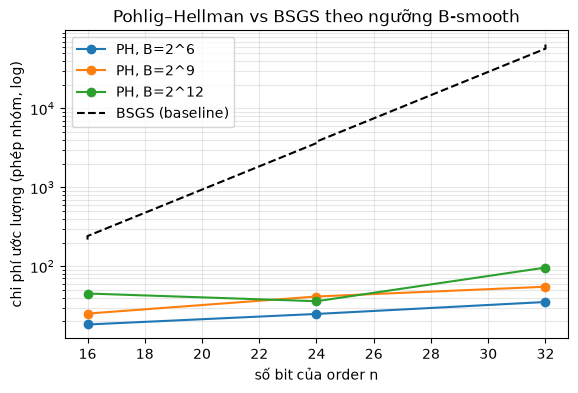

Hệ số tăng tốc PH trung bình theo từng ngưỡng B:
  B=2^6   (64    ) -> speedup trung bình = 596.3x
  B=2^9   (512   ) -> speedup trung bình = 423.9x
  B=2^12  (4096  ) -> speedup trung bình = 256.1x


In [12]:
import matplotlib.pyplot as plt

analysis = []
for line in csv.DictReader(open("../data/smooth_curve_analysis.csv", encoding="utf-8")):
    line["n_bits"] = int(line["n_bits"]); line["smooth_bound"] = int(line["smooth_bound"])
    line["estimated_bsgs_cost"] = float(line["estimated_bsgs_cost"])
    line["estimated_ph_cost"] = float(line["estimated_ph_cost"])
    analysis.append(line)

by_bound: Dict[int, List[dict]] = {}
for a in analysis:
    by_bound.setdefault(a["smooth_bound"], []).append(a)

plt.figure(figsize=(6.5, 4))
for B, items in sorted(by_bound.items()):
    items.sort(key=lambda x: x["n_bits"])
    xs = [i["n_bits"] for i in items]
    ph = [i["estimated_ph_cost"] for i in items]
    plt.semilogy(xs, ph, "o-", label=f"PH, B=2^{B.bit_length()-1}")
bsgs_ref = sorted({(a["n_bits"], a["estimated_bsgs_cost"]) for a in analysis})
plt.semilogy([x for x, _ in bsgs_ref], [y for _, y in bsgs_ref], "k--", label="BSGS (baseline)")
plt.xlabel("số bit của order n"); plt.ylabel("chi phí ước lượng (phép nhóm, log)")
plt.title("Pohlig–Hellman vs BSGS theo ngưỡng B-smooth")
plt.grid(alpha=.3, which="both"); plt.legend()
plt.show()

print("Hệ số tăng tốc PH trung bình theo từng ngưỡng B:")
for B, items in sorted(by_bound.items()):
    avg = sum(i["estimated_bsgs_cost"] / i["estimated_ph_cost"] for i in items) / len(items)
    print(f"  B=2^{B.bit_length()-1:<3} ({B:<6}) -> speedup trung bình = {avg:.1f}x")

### 6c. Kiểm tra "phát hiện lỗi"

Xác nhận `verify_row` bắt được dữ liệu sai ngay cả trên curve do pipeline smooth sinh ra.

In [13]:
good = generate_curve(20, mode="smooth", seed=5)
print("Bản ghi gốc        :", verify_row(good))

bad = dict(good)
bad["largest_prime_factor_n"] = str(int(good["largest_prime_factor_n"]) + 2)
print("Sửa largest_prime_factor_n:", verify_row(bad, recount=False))

Bản ghi gốc        : []
Sửa largest_prime_factor_n: ['largest_prime_factor_n sai']


## Tổng kết

**Đã bổ sung so với `toy_curve_gen.ipynb`:**
- Ước lượng chi phí lý thuyết (`estimate_bsgs_cost`, `estimate_ph_cost`, `ph_speedup`) dựa trên phân tích thừa số
  của order — dùng được ngay cho `docs/track_a_report.md` và để chọn tham số cho `pohlig_hellman.py`.
- `smoothness_profile`: tóm tắt độ smooth của một bản ghi D1 theo nhiều ngưỡng $B$ chuẩn.
- `generate_smooth_curve_batch` + `write_analysis_csv`: sinh **lưới** curve smooth theo (số bit, ngưỡng $B$), ghi
  ra đúng 2 file — `data/D1_smooth_curves.csv` (chuẩn D1, ghép được vào `data/D1_curves.csv` chung) và
  `data/smooth_curve_analysis.csv` (phụ, phục vụ biểu đồ/so sánh, không phá schema chính).
- `selftest()` + CLI `main()` theo đúng convention của T2, sẵn sàng chuyển thành `curves/gen_smooth_curves.py`.

**Giới hạn đã biết:**
- Chi phí `estimate_ph_cost` là ước lượng bậc độ lớn ($\sum e_i\sqrt{q_i}$ phép nhóm), không tính overhead CRT hay
  hằng số cài đặt — con số thực đo được ở `test_pohlig_hellman.py` có thể lệch vài lần.
- Curve ở đây vẫn giới hạn ≤ 40 bit như T2 (Miller–Rabin tất định, Python thuần).
- Không có hiện thực Pohlig–Hellman thật trong notebook này

---

## Tài liệu tham khảo

**Kế thừa từ `toy_curve_gen.ipynb`:** R. Schoof (1995); Cremona–Sutherland; A. Sutherland MIT 18.783; Wikipedia
*Counting points on elliptic curves*; NIST SP 800-186 (2023); FIPS 186-5; RFC 6090; Hankerson–Menezes–Vanstone,
*Guide to Elliptic Curve Cryptography*; Washington, *Elliptic Curves*; Silverman, *The Arithmetic of Elliptic
Curves*.

**Bổ sung cho notebook này (đã tra cứu trực tuyến trong phiên này):**
1. Wikipedia, *Pohlig–Hellman algorithm* — định nghĩa, trường hợp nhóm cấp lũy thừa nguyên tố, công thức độ phức
   tạp tổng quát $\sum_i e_i\sqrt{q_i}$ khi order là smooth, và trường hợp xấu nhất (order nguyên tố) suy biến về
   BSGS. <https://en.wikipedia.org/wiki/Pohlig%E2%80%93Hellman_algorithm>
2. S. D. Galbraith, *Mathematics of Public Key Cryptography*, Chương 13 "The Pohlig-Hellman method" (ghi chú giảng
   dạy, Đại học Auckland) — định nghĩa B-smooth, Định lý 13.2.5 về độ phức tạp, và nhận xét "thừa số nhỏ không cho
   thêm an toàn nên dùng order nguyên tố lớn trong thực tế". <https://www.math.auckland.ac.nz/~sgal018/crypto-book/ch13.pdf>
3. F. Pintore, *Factorisation and Discrete-Logarithm Algorithms* (bài giảng, University of Oxford) — minh hoạ
   Pohlig–Hellman qua phép chiếu nhóm thương và nhận xét #E(Fp) có thể smooth ngay cả khi p−1 không smooth.
   <https://courses.maths.ox.ac.uk/mod/resource/view.php?id=46315>
4. Bài báo (Cambridge Core) về tương đương DHP/DLP trên đường cong elliptic — mô tả việc dùng phép nhân phức để
   dựng đường cong có order smooth rồi áp dụng biến thể Pohlig–Hellman theo từng thừa số nguyên tố của $\#E$.
   <https://resolve.cambridge.org/core/services/aop-cambridge-core/content/view/7921885D6F3CDA5DEDE5238BD72EA70F/S1461157000001042a.pdf>
5. S. C. Pohlig, M. E. Hellman (1978), *An improved algorithm for computing logarithms over GF(p) and its
   cryptographic significance* — công bố gốc của thuật toán (tham chiếu qua Wikipedia ở mục 1).